# Lab 08 - Pretrained Transformers and BERT Fine-Tuning

## Chạy trên Google Colab

In [5]:
import os, sys

IN_COLAB = "google.colab" in sys.modules

# Thư mục chứa train.csv/val.csv/test.csv trên Google Drive (để None nếu muốn tự tải aclImdb)
DRIVE_SPLIT_DIR = None   # ví dụ: "/content/drive/MyDrive/NLP/lab04/datasets/splits"

if IN_COLAB:
    !pip install -q transformers datasets psutil
    if DRIVE_SPLIT_DIR is not None:
        from google.colab import drive
        drive.mount("/content/drive")
    os.makedirs("/content/lab08", exist_ok=True)
    os.chdir("/content/lab08")
print("IN_COLAB =", IN_COLAB, "| cwd =", os.getcwd())


IN_COLAB = True | cwd = /content/lab08


In [6]:
import os
import time
import random
import platform

# Đảm bảo thư mục làm việc luôn là thư mục lab08
if not IN_COLAB and os.path.basename(os.getcwd()) != "lab08" and os.path.exists("lab08"):
    os.chdir("lab08")
print(f"Thư mục làm việc hiện tại: {os.getcwd()}")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from transformers import (AutoTokenizer, AutoConfig, AutoModel, AutoModelForMaskedLM,
                          get_linear_schedule_with_warmup)

try:
    import psutil
except ImportError:
    psutil = None

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Thư mục làm việc hiện tại: /content/lab08
Device: cuda


In [7]:
# Cấu hình chung cho toàn bộ thí nghiệm
SEED = 42

# Tokenizer dùng cho phần Tokenization & MLM (khớp với calculations.md)
CALC_MODEL = "bert-base-uncased"

# Model dùng cho các thí nghiệm fine-tuning.
# - CPU: BERT-mini (4 layers, hidden 256, ~11M params) để chạy nổi.
# - GPU (Colab T4): bert-base-uncased (12 layers, hidden 768, ~110M params).
# Muốn cố định một model thì gán thẳng MODEL_NAME = "...".
MODEL_NAME = "bert-base-uncased" if torch.cuda.is_available() else "google/bert_uncased_L-4_H-256_A-4"
print("MODEL_NAME =", MODEL_NAME)

# Kích thước tập con (giảm để chạy được trên CPU). Đặt None để dùng toàn bộ.
N_TRAIN = 4000
N_VAL = 1000
N_TEST = 1000
N_DOMAIN_B = 1000

MAX_LEN = 128
BATCH_SIZE = 32
EPOCHS = 2

LR_FINETUNE = 5e-5   # pretrained + fine-tuning toàn bộ
LR_FROZEN = 1e-3     # chỉ train classification head
LR_SCRATCH = 1e-4    # cùng kiến trúc, khởi tạo ngẫu nhiên

DATA_FRACTIONS = [0.10, 0.25, 0.50, 1.00]
SEQ_LENGTHS = [64, 128, 256]
RUN_SCRATCH_CURVE = True   # chạy thêm from-scratch cho Experiment 3 (phục vụ Prediction 3 / Q1)

LABEL_NAMES = ["negative", "positive"]


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()
all_results = []   # gom kết quả để ghi results.csv

MODEL_NAME = bert-base-uncased


## Chuẩn bị dữ liệu IMDb

In [8]:
def read_aclimdb_from_stanford():
    """Tải aclImdb gốc từ Stanford rồi đọc các file .txt."""
    import tarfile, urllib.request
    base = "datasets/aclImdb"
    if not os.path.exists(base):
        os.makedirs("datasets", exist_ok=True)
        tar_path = "datasets/aclImdb_v1.tar.gz"
        if not os.path.exists(tar_path):
            print("Đang tải aclImdb từ Stanford (~80MB)...")
            urllib.request.urlretrieve("https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz",
                                       tar_path + ".part")
            os.rename(tar_path + ".part", tar_path)
        with tarfile.open(tar_path) as tar:
            tar.extractall("datasets")
    rows = []
    for split in ["train", "test"]:
        for label in ["pos", "neg"]:
            folder = os.path.join(base, split, label)
            for fname in sorted(os.listdir(folder)):
                if fname.endswith(".txt"):
                    with open(os.path.join(folder, fname), encoding="utf-8") as f:
                        rows.append({"text": f.read(), "label": label})
    return pd.DataFrame(rows)


def read_aclimdb_from_hf():
    """Cùng bộ aclImdb (25k train + 25k test) nhưng tải từ Hugging Face Hub."""
    from datasets import load_dataset
    print("Đang tải IMDb từ Hugging Face (stanfordnlp/imdb)...")
    ds = load_dataset("stanfordnlp/imdb")
    df = pd.concat([ds["train"].to_pandas(), ds["test"].to_pandas()], ignore_index=True)
    df["label"] = df["label"].map({0: "neg", 1: "pos"})
    return df[["text", "label"]]


def build_splits_from_aclimdb(split_dir="datasets/splits"):
    """Tạo splits giống lab04: gộp train+test, bỏ trùng, chia 70/15/15 stratified."""
    from sklearn.model_selection import train_test_split
    try:
        df_all = read_aclimdb_from_stanford()
    except Exception as e:
        print(f"Không tải được từ Stanford ({e}) -> chuyển sang Hugging Face.")
        df_all = read_aclimdb_from_hf()
    df_all = df_all.drop_duplicates(subset=["text"]).reset_index(drop=True)
    tr, tmp = train_test_split(df_all, test_size=0.30, random_state=42, stratify=df_all["label"])
    va, te = train_test_split(tmp, test_size=0.50, random_state=42, stratify=tmp["label"])
    os.makedirs(split_dir, exist_ok=True)
    for name, d in [("train", tr), ("val", va), ("test", te)]:
        d.to_csv(os.path.join(split_dir, f"{name}.csv"), index=False)
    return split_dir


def get_split_dir():
    candidates = [DRIVE_SPLIT_DIR, "../lab04/datasets/splits", "../lab07/datasets/splits", "datasets/splits"]
    for path in candidates:
        if path and os.path.exists(os.path.join(path, "train.csv")):
            return path
    print("Không tìm thấy splits có sẵn -> tạo mới từ aclImdb.")
    return build_splits_from_aclimdb()


def load_split(path):
    df = pd.read_csv(path)
    # Nhãn trong file là "pos"/"neg" -> chuyển sang 1/0 (khớp LABEL_NAMES và Amazon polarity)
    if df["label"].dtype == object or str(df["label"].dtype).startswith("str"):
        df["label"] = df["label"].map({"neg": 0, "pos": 1})
    return df[["text", "label"]].astype({"label": int})


def stratified_sample(df, n, seed=SEED):
    if n is None or n >= len(df):
        return df.reset_index(drop=True)
    frac = n / len(df)
    out = df.groupby("label", group_keys=False).sample(frac=frac, random_state=seed)
    return out.sample(frac=1.0, random_state=seed).reset_index(drop=True)


split_dir = get_split_dir()
print(f"Thư mục dữ liệu: {split_dir}")

df_train_full = load_split(os.path.join(split_dir, "train.csv"))
df_val_full = load_split(os.path.join(split_dir, "val.csv"))
df_test_full = load_split(os.path.join(split_dir, "test.csv"))

df_train = stratified_sample(df_train_full, N_TRAIN)
df_val = stratified_sample(df_val_full, N_VAL)
df_test = stratified_sample(df_test_full, N_TEST)

print(f"Full:   Train = {len(df_train_full):,}, Val = {len(df_val_full):,}, Test = {len(df_test_full):,}")
print(f"Subset: Train = {len(df_train):,}, Val = {len(df_val):,}, Test = {len(df_test):,}")
print("Phân bố nhãn train:", df_train["label"].value_counts().to_dict())

Không tìm thấy splits có sẵn -> tạo mới từ aclImdb.
Đang tải aclImdb từ Stanford (~80MB)...
Không tải được từ Stanford (<urlopen error [Errno 111] Connection refused>) -> chuyển sang Hugging Face.
Đang tải IMDb từ Hugging Face (stanfordnlp/imdb)...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

... (3 outputs left out)

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Thư mục dữ liệu: datasets/splits
Full:   Train = 34,707, Val = 7,437, Test = 7,438
Subset: Train = 4,000, Val = 1,000, Test = 1,000
Phân bố nhãn train: {1: 2008, 0: 1992}


## Tokenization & Attention Mask (Mục 10 & 12.1)

In [9]:
calc_tokenizer = AutoTokenizer.from_pretrained(CALC_MODEL)

text = "The cats are playing."
encoded = calc_tokenizer(text)
tokens_with_special = calc_tokenizer.convert_ids_to_tokens(encoded["input_ids"])
subword_tokens = calc_tokenizer.tokenize(text)

print("Text:              ", text)
print("Subword tokens:    ", subword_tokens)
print("Token sequence:    ", tokens_with_special)
print("Token IDs:         ", encoded["input_ids"])
print("Attention mask:    ", encoded["attention_mask"])
print("Special tokens:    ", [t for t in tokens_with_special if t in calc_tokenizer.all_special_tokens])
print()
print("Số words (tách theo khoảng trắng):", len(text.split()))
print("Số tokens (kèm special tokens):   ", len(tokens_with_special))
print("Số subword tokens:                ", len(subword_tokens))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Text:               The cats are playing.
Subword tokens:     ['the', 'cats', 'are', 'playing', '.']
Token sequence:     ['[CLS]', 'the', 'cats', 'are', 'playing', '.', '[SEP]']
Token IDs:          [101, 1996, 8870, 2024, 2652, 1012, 102]
Attention mask:     [1, 1, 1, 1, 1, 1, 1]
Special tokens:     ['[CLS]', '[SEP]']

Số words (tách theo khoảng trắng): 4
Số tokens (kèm special tokens):    7
Số subword tokens:                 5


In [10]:
# Bảng special tokens của tokenizer
special_df = pd.DataFrame({
    "Token": calc_tokenizer.all_special_tokens,
    "ID": calc_tokenizer.all_special_ids,
})
print(special_df.to_string(index=False))

# Ví dụ subword với từ dài / từ hiếm
for w in ["unbelievable", "tokenization", "catss", "playingg"]:
    print(f"{w:15s} -> {calc_tokenizer.tokenize(w)}")

 Token  ID
 [UNK] 100
 [SEP] 102
 [PAD]   0
 [CLS] 101
[MASK] 103
unbelievable    -> ['unbelievable']
tokenization    -> ['token', '##ization']
catss           -> ['cats', '##s']
playingg        -> ['playing', '##g']


In [11]:
# Tokenize theo batch với padding/truncation (Mục 12.1)
batch_texts = ["The cats are playing.", "The cat eats fish.", "This movie is great!"]
tokens = calc_tokenizer(
    batch_texts,
    padding=True,
    truncation=True,
    return_tensors="pt"
)

print("tokens.keys():", list(tokens.keys()))
print("input_ids shape:     ", tokens["input_ids"].shape)
print("attention_mask shape:", tokens["attention_mask"].shape)
for i, t in enumerate(batch_texts):
    print(f"\n{t}")
    print("  tokens:        ", calc_tokenizer.convert_ids_to_tokens(tokens["input_ids"][i]))
    print("  input_ids:     ", tokens["input_ids"][i].tolist())
    print("  attention_mask:", tokens["attention_mask"][i].tolist())

# Ví dụ cặp câu: [CLS] sentence A [SEP] sentence B [SEP]
pair = calc_tokenizer("The cat eats fish.", "It is hungry.")
print("\nSentence pair:  ", calc_tokenizer.convert_ids_to_tokens(pair["input_ids"]))
print("token_type_ids: ", pair["token_type_ids"])

tokens.keys(): ['input_ids', 'token_type_ids', 'attention_mask']
input_ids shape:      torch.Size([3, 7])
attention_mask shape: torch.Size([3, 7])

The cats are playing.
  tokens:         ['[CLS]', 'the', 'cats', 'are', 'playing', '.', '[SEP]']
  input_ids:      [101, 1996, 8870, 2024, 2652, 1012, 102]
  attention_mask: [1, 1, 1, 1, 1, 1, 1]

The cat eats fish.
  tokens:         ['[CLS]', 'the', 'cat', 'eats', 'fish', '.', '[SEP]']
  input_ids:      [101, 1996, 4937, 20323, 3869, 1012, 102]
  attention_mask: [1, 1, 1, 1, 1, 1, 1]

This movie is great!
  tokens:         ['[CLS]', 'this', 'movie', 'is', 'great', '!', '[SEP]']
  input_ids:      [101, 2023, 3185, 2003, 2307, 999, 102]
  attention_mask: [1, 1, 1, 1, 1, 1, 1]

Sentence pair:   ['[CLS]', 'the', 'cat', 'eats', 'fish', '.', '[SEP]', 'it', 'is', 'hungry', '.', '[SEP]']
token_type_ids:  [0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1]


## Masked Language Modeling với pretrained BERT (Mục 8 & 9)

In [12]:
mlm_model = AutoModelForMaskedLM.from_pretrained(CALC_MODEL).to(device)
mlm_model.eval()

mlm_text = "The cat [MASK] fish."
mlm_inputs = calc_tokenizer(mlm_text, return_tensors="pt").to(device)
mask_pos = (mlm_inputs["input_ids"][0] == calc_tokenizer.mask_token_id).nonzero().item()

with torch.no_grad():
    mlm_logits = mlm_model(**mlm_inputs).logits[0, mask_pos]
mlm_probs = F.softmax(mlm_logits, dim=-1)

top_p, top_ids = mlm_probs.topk(10)
print(f"Top-10 dự đoán cho [MASK] trong '{mlm_text}':")
for p, i in zip(top_p.tolist(), top_ids.tolist()):
    print(f"  {calc_tokenizer.convert_ids_to_tokens(i):10s} {p:.4f}")

# Xác suất và loss của các token trong Calculation Exercise 1
print()
for w in ["cat", "dog", "eats", "fish"]:
    wid = calc_tokenizer.convert_tokens_to_ids(w)
    p = mlm_probs[wid].item()
    print(f"P({w:5s}) = {p:.6f}   -log P = {-np.log(p):.4f}")

del mlm_model

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Top-10 dự đoán cho [MASK] trong 'The cat [MASK] fish.':
  and        0.5909
  -          0.0706
  .          0.0401
  or         0.0209
  is         0.0198
  ,          0.0180
  the        0.0172
  of         0.0115
  was        0.0105
  with       0.0104

P(cat  ) = 0.000035   -log P = 10.2473
P(dog  ) = 0.000034   -log P = 10.3004
P(eats ) = 0.003501   -log P = 5.6548
P(fish ) = 0.000037   -log P = 10.2049


## Core Implementation - Classification Head (Mục 13)

In [13]:
class PretrainedClassifier(nn.Module):
    """Input IDs -> Transformer encoder -> [CLS] representation -> Linear -> logits."""
    def __init__(self, model_name, num_classes=2, from_scratch=False, freeze_encoder=False, dropout=0.1):
        super().__init__()
        if from_scratch:
            # Cùng kiến trúc nhưng trọng số khởi tạo ngẫu nhiên
            config = AutoConfig.from_pretrained(model_name)
            self.encoder = AutoModel.from_config(config, add_pooling_layer=False)
        else:
            self.encoder = AutoModel.from_pretrained(model_name, add_pooling_layer=False)

        self.freeze_encoder = freeze_encoder
        if freeze_encoder:
            for p in self.encoder.parameters():
                p.requires_grad = False

        hidden_size = self.encoder.config.hidden_size
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_classes)   # task-specific head

    def forward(self, input_ids, attention_mask):
        with torch.set_grad_enabled(torch.is_grad_enabled() and not self.freeze_encoder):
            outputs = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        cls_repr = outputs.last_hidden_state[:, 0]               # vector của [CLS]
        return self.classifier(self.dropout(cls_repr))


def count_parameters(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if (p.requires_grad or not trainable_only))


tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Kiểm tra shape qua từng bước của pipeline
demo_model = PretrainedClassifier(MODEL_NAME).eval()
demo_inputs = tokenizer(batch_texts, padding=True, truncation=True, return_tensors="pt")
with torch.no_grad():
    demo_hidden = demo_model.encoder(**{k: demo_inputs[k] for k in ["input_ids", "attention_mask"]}).last_hidden_state
    demo_logits = demo_model(demo_inputs["input_ids"], demo_inputs["attention_mask"])
print("input_ids:                 ", tuple(demo_inputs["input_ids"].shape))
print("contextual representations:", tuple(demo_hidden.shape))
print("[CLS] representation:      ", tuple(demo_hidden[:, 0].shape))
print("class logits:              ", tuple(demo_logits.shape))
print("softmax probs:             ", F.softmax(demo_logits, dim=-1))
print(f"Total params: {count_parameters(demo_model):,}")
del demo_model

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


input_ids:                  (3, 7)
contextual representations: (3, 7, 768)
[CLS] representation:       (3, 768)
class logits:               (3, 2)
softmax probs:              tensor([[0.4725, 0.5275],
        [0.5147, 0.4853],
        [0.5649, 0.4351]])
Total params: 108,893,186


## Hàm huấn luyện và đánh giá

In [14]:
def make_loader(df, max_len, shuffle=False, batch_size=BATCH_SIZE):
    enc = tokenizer(df["text"].tolist(), padding="max_length", truncation=True,
                    max_length=max_len, return_tensors="pt")
    labels = torch.tensor(df["label"].values, dtype=torch.long)
    ds = TensorDataset(enc["input_ids"], enc["attention_mask"], labels)
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=g if shuffle else None)


def current_memory_mb():
    if device.type == "cuda":
        return torch.cuda.max_memory_allocated() / 1024 ** 2
    if psutil is not None:
        return psutil.Process().memory_info().rss / 1024 ** 2
    return float("nan")


@torch.no_grad()
def predict(model, loader):
    model.eval()
    all_probs, all_labels, total_loss = [], [], 0.0
    for input_ids, mask, y in loader:
        input_ids, mask, y = input_ids.to(device), mask.to(device), y.to(device)
        logits = model(input_ids, mask)
        total_loss += F.cross_entropy(logits, y, reduction="sum").item()
        all_probs.append(F.softmax(logits, dim=-1).cpu())
        all_labels.append(y.cpu())
    probs = torch.cat(all_probs).numpy()
    labels = torch.cat(all_labels).numpy()
    return probs, labels, total_loss / len(labels)


def compute_metrics(labels, probs):
    preds = probs.argmax(axis=1)
    return {
        "Accuracy": accuracy_score(labels, preds),
        "Precision": precision_score(labels, preds, zero_division=0),
        "Recall": recall_score(labels, preds, zero_division=0),
        "F1": f1_score(labels, preds, zero_division=0),
    }


def train_model(model, train_loader, val_loader, epochs=EPOCHS, lr=LR_FINETUNE, weight_decay=0.01):
    model.to(device)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    total_steps = epochs * len(train_loader)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    base_mem = current_memory_mb() if device.type == "cpu" else 0.0
    peak_mem = base_mem

    history = []
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        running_loss, n_seen = 0.0, 0
        for input_ids, mask, y in train_loader:
            input_ids, mask, y = input_ids.to(device), mask.to(device), y.to(device)
            optimizer.zero_grad()
            loss = F.cross_entropy(model(input_ids, mask), y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            optimizer.step()
            scheduler.step()
            running_loss += loss.item() * len(y)
            n_seen += len(y)
            peak_mem = max(peak_mem, current_memory_mb())

        val_probs, val_labels, val_loss = predict(model, val_loader)
        val_acc = compute_metrics(val_labels, val_probs)["Accuracy"]
        history.append({"epoch": epoch, "train_loss": running_loss / n_seen,
                        "val_loss": val_loss, "val_acc": val_acc})
        print(f"  Epoch {epoch}/{epochs} | train_loss {running_loss / n_seen:.4f} "
              f"| val_loss {val_loss:.4f} | val_acc {val_acc:.4f}")
    train_time = time.time() - start
    used_mem = peak_mem - base_mem if device.type == "cpu" else peak_mem
    return history, train_time, used_mem


def run_experiment(experiment, setting, train_df=None, max_len=MAX_LEN, from_scratch=False,
                   freeze_encoder=False, epochs=EPOCHS, lr=None):
    train_df = df_train if train_df is None else train_df
    if lr is None:
        lr = LR_SCRATCH if from_scratch else (LR_FROZEN if freeze_encoder else LR_FINETUNE)
    print(f"\n>>> [{experiment}] {setting} | train={len(train_df)} | max_len={max_len} | lr={lr}")

    set_seed(SEED)
    train_loader = make_loader(train_df, max_len, shuffle=True)
    val_loader = make_loader(df_val, max_len)
    test_loader = make_loader(df_test, max_len)

    model = PretrainedClassifier(MODEL_NAME, from_scratch=from_scratch, freeze_encoder=freeze_encoder)
    history, train_time, mem = train_model(model, train_loader, val_loader, epochs=epochs, lr=lr)
    probs, labels, _ = predict(model, test_loader)
    metrics = compute_metrics(labels, probs)

    row = {
        "Experiment": experiment,
        "Setting": setting,
        "Init": "random" if from_scratch else "pretrained",
        "Encoder trainable": not freeze_encoder,
        "Train size": len(train_df),
        "Max length": max_len,
        **{k: round(v, 4) for k, v in metrics.items()},
        "Training time (s)": round(train_time, 2),
        "Total params": count_parameters(model),
        "Trainable params": count_parameters(model, trainable_only=True),
        "Peak memory (MB)": round(mem, 1),
    }
    all_results.append(row)
    print(f"  Test: Acc {metrics['Accuracy']:.4f} | F1 {metrics['F1']:.4f} | time {train_time:.1f}s")
    return {"model": model, "row": row, "history": history, "probs": probs, "labels": labels}

## Experiment 1 - Pretrained vs From Scratch (Mục 14)

In [15]:
run_scratch = run_experiment("Exp1", "Transformer from scratch", from_scratch=True)
run_finetune = run_experiment("Exp1", "Pretrained Transformer (fine-tuning)")


>>> [Exp1] Transformer from scratch | train=4000 | max_len=128 | lr=0.0001
  Epoch 1/2 | train_loss 0.7947 | val_loss 0.6933 | val_acc 0.4980
  Epoch 2/2 | train_loss 0.7031 | val_loss 0.6933 | val_acc 0.4980
  Test: Acc 0.4980 | F1 0.0000 | time 170.2s

>>> [Exp1] Pretrained Transformer (fine-tuning) | train=4000 | max_len=128 | lr=5e-05


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Epoch 1/2 | train_loss 0.4129 | val_loss 0.3319 | val_acc 0.8450
  Epoch 2/2 | train_loss 0.1628 | val_loss 0.4056 | val_acc 0.8630
  Test: Acc 0.8600 | F1 0.8649 | time 178.3s


In [16]:
exp1_df = pd.DataFrame([run_scratch["row"], run_finetune["row"]])
exp1_df = exp1_df[["Setting", "Accuracy", "F1", "Training time (s)", "Total params"]]
exp1_df.columns = ["Model", "Accuracy", "F1", "Training time (s)", "# Parameters"]
exp1_df["Model"] = ["Transformer from scratch", "Pretrained Transformer"]
print(exp1_df.to_string(index=False))

                   Model  Accuracy     F1  Training time (s)  # Parameters
Transformer from scratch     0.498 0.0000             170.19     108893186
  Pretrained Transformer     0.860 0.8649             178.34     108893186


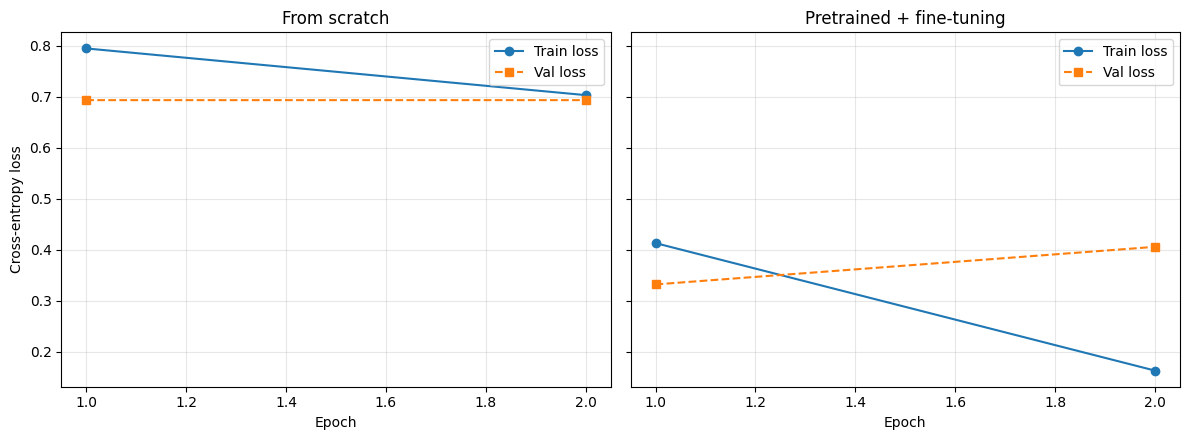

In [17]:
# Learning curves của hai model
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (name, run) in zip(axes, [("From scratch", run_scratch), ("Pretrained + fine-tuning", run_finetune)]):
    hist = pd.DataFrame(run["history"])
    ax.plot(hist["epoch"], hist["train_loss"], marker="o", label="Train loss")
    ax.plot(hist["epoch"], hist["val_loss"], marker="s", linestyle="--", label="Val loss")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.grid(True, alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Cross-entropy loss")
plt.tight_layout()
plt.savefig("learning_curves.png", dpi=150)
plt.show()

## Experiment 2 - Feature Extraction vs Fine-Tuning (Mục 15)

In [18]:
run_frozen = run_experiment("Exp2", "Frozen encoder (feature extraction)", freeze_encoder=True)

exp2_df = pd.DataFrame([run_frozen["row"], run_finetune["row"]])
exp2_df = exp2_df[["Encoder trainable", "Accuracy", "F1", "Training time (s)", "Trainable params"]]
exp2_df.insert(0, "Mode", ["Frozen", "Fine-tuning"])
exp2_df["Encoder trainable?"] = exp2_df.pop("Encoder trainable").map({True: "Yes", False: "No"})
print(exp2_df[["Mode", "Encoder trainable?", "Accuracy", "F1", "Training time (s)", "Trainable params"]].to_string(index=False))


>>> [Exp2] Frozen encoder (feature extraction) | train=4000 | max_len=128 | lr=0.001


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Epoch 1/2 | train_loss 0.5938 | val_loss 0.5397 | val_acc 0.7240
  Epoch 2/2 | train_loss 0.5120 | val_loss 0.5207 | val_acc 0.7390
  Test: Acc 0.7790 | F1 0.7877 | time 65.7s
       Mode Encoder trainable?  Accuracy     F1  Training time (s)  Trainable params
     Frozen                 No     0.779 0.7877              65.68              1538
Fine-tuning                Yes     0.860 0.8649             178.34         108893186


## Experiment 3 - Amount of Training Data (Mục 16)

In [19]:
data_rows = []
for frac in DATA_FRACTIONS:
    if frac == 1.0:
        # 100% đã chạy ở Experiment 1
        pre_row, scr_row = run_finetune["row"], run_scratch["row"]
    else:
        subset = stratified_sample(df_train, int(round(frac * len(df_train))))
        pre_row = run_experiment("Exp3", f"Pretrained {int(frac * 100)}%", train_df=subset)["row"]
        scr_row = (run_experiment("Exp3", f"From scratch {int(frac * 100)}%", train_df=subset,
                                  from_scratch=True)["row"] if RUN_SCRATCH_CURVE else None)
    data_rows.append({"Model": "Pretrained", "Training data": f"{int(frac * 100)}%", "Fraction": frac,
                      "Train size": pre_row["Train size"], "Accuracy": pre_row["Accuracy"], "F1": pre_row["F1"]})
    if scr_row is not None:
        data_rows.append({"Model": "From scratch", "Training data": f"{int(frac * 100)}%", "Fraction": frac,
                          "Train size": scr_row["Train size"], "Accuracy": scr_row["Accuracy"], "F1": scr_row["F1"]})

exp3_df = pd.DataFrame(data_rows)
print(exp3_df.drop(columns="Fraction").to_string(index=False))


>>> [Exp3] Pretrained 10% | train=400 | max_len=128 | lr=5e-05


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Epoch 1/2 | train_loss 0.6481 | val_loss 0.5148 | val_acc 0.7670
  Epoch 2/2 | train_loss 0.3666 | val_loss 0.4160 | val_acc 0.8100
  Test: Acc 0.8260 | F1 0.8249 | time 29.3s

>>> [Exp3] From scratch 10% | train=400 | max_len=128 | lr=0.0001
  Epoch 1/2 | train_loss 1.6040 | val_loss 0.7327 | val_acc 0.4980
  Epoch 2/2 | train_loss 0.7549 | val_loss 0.6940 | val_acc 0.5020
  Test: Acc 0.5020 | F1 0.6684 | time 29.3s

>>> [Exp3] Pretrained 25% | train=1000 | max_len=128 | lr=5e-05


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Epoch 1/2 | train_loss 0.4996 | val_loss 0.4832 | val_acc 0.7990
  Epoch 2/2 | train_loss 0.2036 | val_loss 0.3999 | val_acc 0.8370
  Test: Acc 0.8440 | F1 0.8474 | time 54.3s

>>> [Exp3] From scratch 25% | train=1000 | max_len=128 | lr=0.0001
  Epoch 1/2 | train_loss 0.9269 | val_loss 0.7465 | val_acc 0.5020
  Epoch 2/2 | train_loss 0.7391 | val_loss 0.6932 | val_acc 0.5020
  Test: Acc 0.5020 | F1 0.6684 | time 54.0s

>>> [Exp3] Pretrained 50% | train=2000 | max_len=128 | lr=5e-05


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Epoch 1/2 | train_loss 0.4652 | val_loss 0.3512 | val_acc 0.8380
  Epoch 2/2 | train_loss 0.2036 | val_loss 0.3857 | val_acc 0.8400
  Test: Acc 0.8470 | F1 0.8475 | time 95.6s

>>> [Exp3] From scratch 50% | train=2000 | max_len=128 | lr=0.0001
  Epoch 1/2 | train_loss 0.7799 | val_loss 0.7225 | val_acc 0.5020
  Epoch 2/2 | train_loss 0.7117 | val_loss 0.6932 | val_acc 0.5020
  Test: Acc 0.5020 | F1 0.6684 | time 95.1s
       Model Training data  Train size  Accuracy     F1
  Pretrained           10%         400     0.826 0.8249
From scratch           10%         400     0.502 0.6684
  Pretrained           25%        1000     0.844 0.8474
From scratch           25%        1000     0.502 0.6684
  Pretrained           50%        2000     0.847 0.8475
From scratch           50%        2000     0.502 0.6684
  Pretrained          100%        4000     0.860 0.8649
From scratch          100%        4000     0.498 0.0000


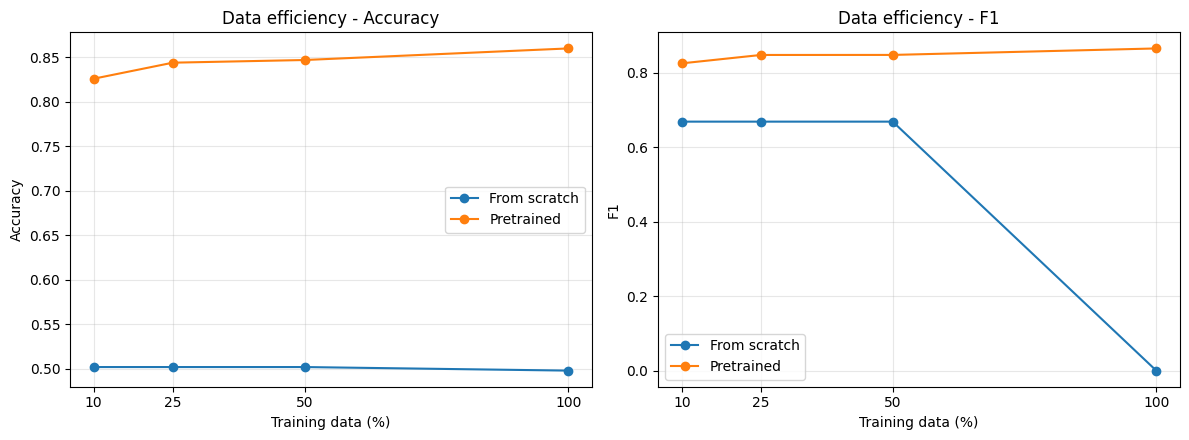

In [20]:
# Vẽ và lưu data_efficiency.png
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric in zip(axes, ["Accuracy", "F1"]):
    for name, grp in exp3_df.groupby("Model"):
        ax.plot(grp["Fraction"] * 100, grp[metric], marker="o", label=name)
    ax.set_xticks([f * 100 for f in DATA_FRACTIONS])
    ax.set_xlabel("Training data (%)")
    ax.set_ylabel(metric)
    ax.set_title(f"Data efficiency - {metric}")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig("data_efficiency.png", dpi=150)
plt.show()

## Experiment 4 - Maximum Sequence Length (Mục 17)

In [21]:
seq_rows = []
for T in SEQ_LENGTHS:
    row = run_finetune["row"] if T == MAX_LEN else run_experiment("Exp4", f"Max length {T}", max_len=T)["row"]
    seq_rows.append({"Max length": T, "Accuracy": row["Accuracy"], "F1": row["F1"],
                     "Training time (s)": row["Training time (s)"], "Peak memory (MB)": row["Peak memory (MB)"]})

exp4_df = pd.DataFrame(seq_rows)
print(exp4_df.to_string(index=False))

# Tỷ lệ truncation của review ở từng max length
lengths = np.array([len(ids) for ids in tokenizer(df_train["text"].tolist())["input_ids"]])
print(f"\nĐộ dài token của review (train): median = {np.median(lengths):.0f}, mean = {lengths.mean():.0f}")
for T in SEQ_LENGTHS:
    print(f"  T = {T:3d}: {np.mean(lengths > T) * 100:.1f}% review bị truncate")


>>> [Exp4] Max length 64 | train=4000 | max_len=64 | lr=5e-05


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Epoch 1/2 | train_loss 0.4980 | val_loss 0.4458 | val_acc 0.7930
  Epoch 2/2 | train_loss 0.2435 | val_loss 0.4814 | val_acc 0.8120
  Test: Acc 0.8230 | F1 0.8277 | time 94.6s

>>> [Exp4] Max length 256 | train=4000 | max_len=256 | lr=5e-05


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Epoch 1/2 | train_loss 0.3502 | val_loss 0.2875 | val_acc 0.8930
  Epoch 2/2 | train_loss 0.1254 | val_loss 0.3421 | val_acc 0.8990
  Test: Acc 0.9030 | F1 0.9048 | time 370.9s
 Max length  Accuracy     F1  Training time (s)  Peak memory (MB)
         64     0.823 0.8277              94.59            4718.1
        128     0.860 0.8649             178.34            4680.8
        256     0.903 0.9048             370.93            8486.3


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (711 > 512). Running this sequence through the model will result in indexing errors



Độ dài token của review (train): median = 234, mean = 309
  T =  64: 97.9% review bị truncate
  T = 128: 89.2% review bị truncate
  T = 256: 44.0% review bị truncate


## Experiment 5 - Domain Shift (Mục 18)

In [22]:
def load_domain_b(n=N_DOMAIN_B):
    """Domain B: Amazon product reviews (positive/negative). Cần: pip install datasets"""
    local_path = "datasets/domain_b.csv"
    if os.path.exists(local_path):
        return stratified_sample(pd.read_csv(local_path), n)
    from datasets import load_dataset
    stream = load_dataset("fancyzhx/amazon_polarity", split="test", streaming=True)
    stream = stream.shuffle(seed=SEED, buffer_size=10_000).take(n)
    df = pd.DataFrame(list(stream))
    df["text"] = df["title"] + ". " + df["content"]
    df = df[["text", "label"]]
    os.makedirs("datasets", exist_ok=True)
    df.to_csv(local_path, index=False)
    return df


df_domain_b = load_domain_b()
print(f"Domain B: {len(df_domain_b)} mẫu, phân bố nhãn {df_domain_b['label'].value_counts().to_dict()}")
print(df_domain_b["text"].iloc[0][:300])

README.md:   0%|          | 0.00/6.81k [00:00<?, ?B/s]

Domain B: 1000 mẫu, phân bố nhãn {1: 516, 0: 484}
Great Mystery - Not So Great Horror Flick. If you like super-natural mysteries, then you'd like this film. It is technically a horror film, but it's really not that frightening (though there is a scene in the movie that made my mother jump about three feet), and as a result, is not for people that w


In [23]:
domain_rows = []
for name, df_eval in [("A: IMDb movie reviews (in-domain)", df_test),
                      ("B: Amazon product reviews (out-of-domain)", df_domain_b)]:
    probs, labels, _ = predict(run_finetune["model"], make_loader(df_eval, MAX_LEN))
    m = compute_metrics(labels, probs)
    domain_rows.append({"Test domain": name, "N": len(labels), **{k: round(v, 4) for k, v in m.items()}})
    all_results.append({"Experiment": "Exp5", "Setting": f"Train IMDb -> test {name}", "Init": "pretrained",
                        "Encoder trainable": True, "Train size": len(df_train), "Max length": MAX_LEN,
                        **{k: round(v, 4) for k, v in m.items()}})
    if name.startswith("B"):
        domain_b_probs, domain_b_labels = probs, labels

exp5_df = pd.DataFrame(domain_rows)
print(exp5_df.to_string(index=False))
print(f"\nPerformance drop (Accuracy): {exp5_df['Accuracy'].iloc[0] - exp5_df['Accuracy'].iloc[1]:+.4f}")
print(f"Performance drop (F1):       {exp5_df['F1'].iloc[0] - exp5_df['F1'].iloc[1]:+.4f}")

                              Test domain    N  Accuracy  Precision  Recall     F1
        A: IMDb movie reviews (in-domain) 1000     0.860     0.8390  0.8924 0.8649
B: Amazon product reviews (out-of-domain) 1000     0.904     0.8621  0.9690 0.9124

Performance drop (Accuracy): -0.0440
Performance drop (F1):       -0.0475


## Application - Sentiment Classification (Mục 19)

Accuracy  : 0.8600
Precision : 0.8390
Recall    : 0.8924
F1        : 0.8649


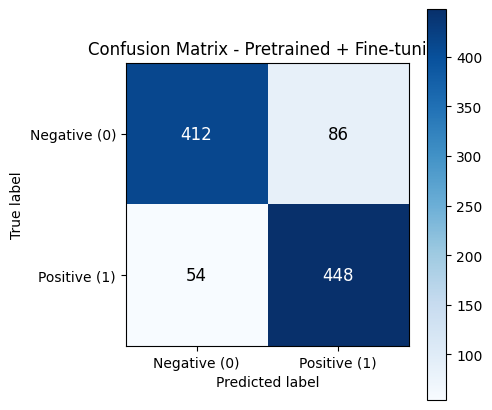

In [24]:
main_probs, main_labels = run_finetune["probs"], run_finetune["labels"]
main_preds = main_probs.argmax(axis=1)
main_metrics = compute_metrics(main_labels, main_probs)
for k, v in main_metrics.items():
    print(f"{k:10s}: {v:.4f}")

# Vẽ và lưu confusion_matrix.png
cm = confusion_matrix(main_labels, main_preds)
fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Negative (0)", "Positive (1)"])
ax.set_yticklabels(["Negative (0)", "Positive (1)"])
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Confusion Matrix - Pretrained + Fine-tuning")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [25]:
@torch.no_grad()
def predict_texts(model, texts, max_len=MAX_LEN):
    model.eval()
    enc = tokenizer(texts, padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(device)
    return F.softmax(model(enc["input_ids"], enc["attention_mask"]), dim=-1).cpu().numpy()


test_sentences = [
    ("Câu ngắn", "Loved it! Absolutely brilliant."),
    ("Phủ định", "The film is not good at all."),
    ("Phủ định kép", "It is not that the movie was bad, I just did not enjoy it."),
    ("Tương phản", "The acting was outstanding, but the plot was a complete disaster."),
    ("Mỉa mai", "Oh great, another two hours of my life I will never get back."),
    ("Mơ hồ", "An unusual experiment with bizarre pacing that will divide audiences."),
]
app_probs = predict_texts(run_finetune["model"], [s for _, s in test_sentences])
app_df = pd.DataFrame({
    "Case": [c for c, _ in test_sentences],
    "Text": [s for _, s in test_sentences],
    "Pred": [LABEL_NAMES[i] for i in app_probs.argmax(axis=1)],
    "Confidence": app_probs.max(axis=1).round(4),
})
print(app_df.to_string(index=False))

        Case                                                                  Text     Pred  Confidence
    Câu ngắn                                       Loved it! Absolutely brilliant. positive      0.9922
    Phủ định                                          The film is not good at all. negative      0.9925
Phủ định kép            It is not that the movie was bad, I just did not enjoy it. negative      0.9891
  Tương phản     The acting was outstanding, but the plot was a complete disaster. negative      0.9883
     Mỉa mai         Oh great, another two hours of my life I will never get back. negative      0.6817
       Mơ hồ An unusual experiment with bizarre pacing that will divide audiences. positive      0.9858


## Error Analysis (Mục 20)

In [26]:
main_conf = main_probs.max(axis=1)
err_df = pd.DataFrame({
    "idx": np.arange(len(main_labels)),
    "Text": df_test["text"].values,
    "True": [LABEL_NAMES[i] for i in main_labels],
    "Pred": [LABEL_NAMES[i] for i in main_preds],
    "Confidence": main_conf.round(4),
    "Num tokens": [len(ids) for ids in tokenizer(df_test["text"].tolist())["input_ids"]],
})
wrong = err_df[err_df["True"] != err_df["Pred"]]

false_pos = wrong[wrong["Pred"] == "positive"].sort_values("Confidence", ascending=False).head(3)
false_neg = wrong[wrong["Pred"] == "negative"].sort_values("Confidence", ascending=False).head(3)
used = set(false_pos["idx"]) | set(false_neg["idx"])
confident_wrong = wrong[~wrong["idx"].isin(used)].sort_values("Confidence", ascending=False).head(2)

error_table = pd.concat([
    false_pos.assign(Group="False positive"),
    false_neg.assign(Group="False negative"),
    confident_wrong.assign(Group="High-confidence wrong"),
])
error_table["Error type"] = ""    # tự điền: negation, sarcasm, long-range dependency, ...
error_table["Hypothesis"] = ""    # tự điền sau khi đọc kỹ từng review
error_table = error_table[["Group", "idx", "Text", "True", "Pred", "Confidence", "Num tokens", "Error type", "Hypothesis"]]
error_table.to_csv("error_samples.csv", index=False)

print(f"Tổng số mẫu sai: {len(wrong)} / {len(err_df)}")
for _, r in error_table.iterrows():
    print(f"\n[{r['Group']}] idx={r['idx']} | True={r['True']} | Pred={r['Pred']} "
          f"| Conf={r['Confidence']} | Tokens={r['Num tokens']}")
    print(r["Text"][:600] + ("..." if len(r["Text"]) > 600 else ""))

Tổng số mẫu sai: 140 / 1000

[False positive] idx=460 | True=negative | Pred=positive | Conf=0.9973000288009644 | Tokens=711
The story of a woman (Ann) on her death bed, her two daughters (Nina and Constance) and her thoughts about her past. The flashbacks are concerning a weekend where young Ann is in the wedding of her friend Lila. At the wedding she meets Harris who will impact her for the rest of her life. Through all the ups and downs of her professional and family life she remembers him as her true love. Her daughter Constance is older, more "responsible," a mother of two and has things together. Nina jumps from boyfriend to boyfriend and job to job and is unsure of her direction in life.<br /><br />First of a...

[False positive] idx=434 | True=negative | Pred=positive | Conf=0.9968000054359436 | Tokens=1067
The figure of empress Elizabeth of Austria (1837-1898) is, indeed, mostly associated with Romy Schneider and the Sissi trilogy by Ernst Marischka (1950s) where beauty, gentl

## Confidence Analysis (Mục 21)

In [27]:
def confidence_bin(c):
    if c >= 0.9:
        return "High (>= 0.9)"
    if c >= 0.7:
        return "Medium (0.7 - 0.9)"
    return "Low (< 0.7)"


conf_df = pd.DataFrame({"confidence": main_conf, "correct": main_preds == main_labels})
conf_df["bin"] = conf_df["confidence"].apply(confidence_bin)
bin_order = ["High (>= 0.9)", "Medium (0.7 - 0.9)", "Low (< 0.7)"]
conf_summary = (conf_df.groupby("bin")
                .agg(N=("correct", "size"), Accuracy=("correct", "mean"), Mean_confidence=("confidence", "mean"))
                .reindex(bin_order).round(4))
print(conf_summary)
print(f"\nSố mẫu sai có confidence >= 0.9: {((~conf_df['correct']) & (conf_df['confidence'] >= 0.9)).sum()}")

                      N  Accuracy  Mean_confidence
bin                                               
High (>= 0.9)       833    0.9172           0.9860
Medium (0.7 - 0.9)  123    0.5610           0.8242
Low (< 0.7)          44    0.6136           0.5972

Số mẫu sai có confidence >= 0.9: 69


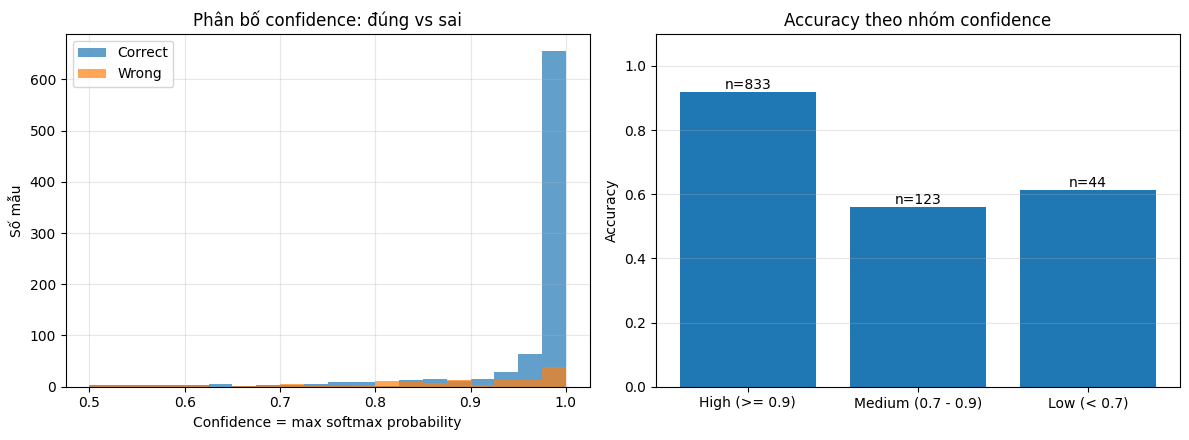

In [28]:
# Vẽ và lưu confidence_analysis.png
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

bins = np.linspace(0.5, 1.0, 21)
axes[0].hist(conf_df.loc[conf_df["correct"], "confidence"], bins=bins, alpha=0.7, label="Correct")
axes[0].hist(conf_df.loc[~conf_df["correct"], "confidence"], bins=bins, alpha=0.7, label="Wrong")
axes[0].set_xlabel("Confidence = max softmax probability")
axes[0].set_ylabel("Số mẫu")
axes[0].set_title("Phân bố confidence: đúng vs sai")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

bars = axes[1].bar(conf_summary.index, conf_summary["Accuracy"])
for bar, n in zip(bars, conf_summary["N"]):
    if not np.isnan(bar.get_height()):
        axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01, f"n={int(n)}", ha="center")
axes[1].set_ylim(0, 1.1)
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy theo nhóm confidence")
axes[1].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("confidence_analysis.png", dpi=150)
plt.show()

## Lưu results.csv

In [29]:
results_df = pd.DataFrame(all_results)
results_df.to_csv("results.csv", index=False)
print(results_df.to_string(index=False))

Experiment                                                      Setting       Init  Encoder trainable  Train size  Max length  Accuracy  Precision  Recall     F1  Training time (s)  Total params  Trainable params  Peak memory (MB)
      Exp1                                     Transformer from scratch     random               True        4000         128     0.498     0.0000  0.0000 0.0000             170.19   108893186.0       108893186.0            3813.2
      Exp1                         Pretrained Transformer (fine-tuning) pretrained               True        4000         128     0.860     0.8390  0.8924 0.8649             178.34   108893186.0       108893186.0            4680.8
      Exp2                          Frozen encoder (feature extraction) pretrained              False        4000         128     0.779     0.7607  0.8167 0.7877              65.68   108893186.0            1538.0            2312.9
      Exp3                                               Pretrained 10% pret

## Reproducibility (Mục 23)

In [30]:
hardware = torch.cuda.get_device_name(0) if device.type == "cuda" else f"CPU: {platform.processor() or platform.machine()}, {os.cpu_count()} cores"
repro = {
    "Model": MODEL_NAME,
    "Tokenizer": MODEL_NAME,
    "Dataset": "IMDb (aclImdb) + Amazon polarity (domain B)",
    "Train split": f"{len(df_train)} mẫu (lấy stratified từ {len(df_train_full)})",
    "Validation split": f"{len(df_val)} mẫu (lấy stratified từ {len(df_val_full)})",
    "Test split": f"{len(df_test)} mẫu (lấy stratified từ {len(df_test_full)})",
    "Max sequence length": MAX_LEN,
    "Batch size": BATCH_SIZE,
    "Learning rate": f"fine-tune {LR_FINETUNE}, frozen {LR_FROZEN}, scratch {LR_SCRATCH}",
    "Epochs": EPOCHS,
    "Optimizer": "AdamW (weight_decay=0.01) + linear warmup 10%",
    "Random seed": SEED,
    "Hardware": hardware,
    "Training time": f"{run_finetune['row']['Training time (s)']} s (pretrained fine-tuning, model chính)",
    "Versions": f"torch {torch.__version__}, transformers {__import__('transformers').__version__}",
}
for k, v in repro.items():
    print(f"{k + ':':22s}{v}")

Model:                bert-base-uncased
Tokenizer:            bert-base-uncased
Dataset:              IMDb (aclImdb) + Amazon polarity (domain B)
Train split:          4000 mẫu (lấy stratified từ 34707)
Validation split:     1000 mẫu (lấy stratified từ 7437)
Test split:           1000 mẫu (lấy stratified từ 7438)
Max sequence length:  128
Batch size:           32
Learning rate:        fine-tune 5e-05, frozen 0.001, scratch 0.0001
Epochs:               2
Optimizer:            AdamW (weight_decay=0.01) + linear warmup 10%
Random seed:          42
Hardware:             Tesla T4
Training time:        178.34 s (pretrained fine-tuning, model chính)
Versions:             torch 2.14.1+cu130, transformers 5.22.1
